# Uygulama 3: Titanic — Eksik Veriden Tahmine
**Makine Öğrenmesi — Google Colab uygulaması**

| Başlık | Açıklama |
|---|---|
| Veri seti | Seaborn Titanic CSV: 891 yolcu |
| Görev | Hayatta kalma durumunu sınıflandırmak |
| Algoritmalar | Lojistik regresyon, karar ağacı |
| Yeni konular | Eksik veri, one-hot kodlama, Pipeline, çapraz doğrulama |

### Bu uygulamada yapacaklarımız
1. Yolcu verisini tanımak
2. Eksik ve kategorik veriyi hazırlamak
3. Modelleri eğitim içindeki doğrulamayla karşılaştırmak
4. Son modeli test etmek ve yeni yolcular için tahmin yapmak

### Çalıştırma
Colab'de **Dosya → Not defteri yükle** ile bu dosyayı açın. Hücreleri yukarıdan aşağıya **Shift + Enter** ile çalıştırın. Her defter bağımsızdır; önceki dersin değişkenlerine ihtiyaç duymaz. Standart Colab Python ortamı ve CPU yeterlidir; GPU seçmeniz gerekmez. pandas, NumPy, Matplotlib, Seaborn ve scikit-learn Colab'de hazırdır.

Dosyada kontrol çalıştırmasının çıktıları bulunur. Kendi çalıştırmanızda sürüme bağlı küçük sayısal farklar olabilir. İnternetten yüklenen veriler için ilk çalıştırmada internet gerekir. Hata durumunda önce önceki hücrelerin çalıştığını kontrol edin.

**Kaynak:** [Seaborn Titanic veri deposu](https://github.com/mwaskom/seaborn-data/blob/master/titanic.csv). OpenML erişimi kontrol sırasında hata verdiği için burada 891 satırlık Seaborn sürümü kullanılıyor; farklı Titanic sürümleri farklı satır sayılarına sahiptir.

## 1. Kütüphaneler
`import`, hazır araçları programa dahil eder. `as pd` gibi ifadeler kısa ad verir. **pandas** tabloyu, **NumPy** sayıları, **Matplotlib/Seaborn** grafikleri, **scikit-learn** modelleri yönetir. Aşağıdaki hücre yalnızca bu ortak araçları hazırlar; model araçlarını ihtiyaç duyduğumuz yerde ekleyeceğiz.

In [1]:
import numpy as np                     # Sayı dizileri ve hesaplamalar
import pandas as pd                    # Tablo verisi
import matplotlib.pyplot as plt        # Grafikler
import seaborn as sns                  # İstatistiksel grafikler
from IPython.display import display
import sklearn
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams.update({"figure.figsize": (8, 5), "figure.dpi": 110,
                     "figure.autolayout": True})
print("pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)

pandas: 3.0.6 | scikit-learn: 1.9.1


## 2. Veriyi yüklemek

`read_csv`, internetteki CSV dosyasını tabloya dönüştürür. Her satır bir yolcudur. Bu hücre için internet gerekir; dosya yüklemeniz gerekmez.

In [2]:
adres = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df = pd.read_csv(adres)
print("Ham tablo:", df.shape)
display(df.head())

Ham tablo: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


**Çıktıyı nasıl okuyalım?**

891 satır bekliyoruz. Ham tabloda birçok sütun olsa da modelde yalnızca tahmin anında bilinebilecek sınırlı bir özellik listesi kullanacağız.

## 3. Özellikleri seçmek ve Türkçeleştirmek

`survived` hedefimizdir: 1 hayatta kaldı, 0 hayatta kalmadı. `sibsp` gemideki kardeş/eş, `parch` ebeveyn/çocuk sayısıdır. Kurtarma botu ve ceset bilgisi gibi olay sonrası sütunlar **veri sızıntısı** yaratacağı için kullanılmaz.

In [3]:
sutunlar = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked", "survived"]
df = df[sutunlar].rename(columns={
    "pclass": "yolcu_sinifi", "sex": "cinsiyet", "age": "yas",
    "sibsp": "kardes_es", "parch": "ebeveyn_cocuk", "fare": "ucret",
    "embarked": "binis_limani", "survived": "hayatta_kaldi"})
sayisal = ["yas", "kardes_es", "ebeveyn_cocuk", "ucret"]
kategorik = ["yolcu_sinifi", "cinsiyet", "binis_limani"]
for sutun in sayisal:
    df[sutun] = pd.to_numeric(df[sutun], errors="coerce")
# Kategorileri metin, eksikleri np.nan olarak tutuyoruz.
for sutun in kategorik:
    df[sutun] = df[sutun].astype(object).map(lambda x: str(x) if pd.notna(x) else np.nan)
df["hayatta_kaldi"] = df["hayatta_kaldi"].astype(int)
display(df.head())

,yolcu_sinifi,cinsiyet,yas,kardes_es,ebeveyn_cocuk,ucret,binis_limani,hayatta_kaldi
0,3,male,22.0,1,0,7.2500,S,0
1,1,female,38.0,1,0,71.2833,C,1
2,3,female,26.0,0,0,7.9250,S,1
3,1,female,35.0,1,0,53.1000,S,1
4,3,male,35.0,0,0,8.0500,S,0


**Çıktıyı nasıl okuyalım?**

Yolcu sınıfını burada kategorik ele alıyoruz. Ücret tarihsel bilet ücretidir; günümüz TL fiyatı değildir. Dönüşümler yalnızca biçimi değiştirir; henüz eksik değer doldurmadık.

## 4. Eksikler ve sınıf dağılımı

Modelden önce `info`, `isna` ve `value_counts` ile tabloyu inceleriz.

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   yolcu_sinifi   891 non-null    str    
 1   cinsiyet       891 non-null    str    
 2   yas            714 non-null    float64
 3   kardes_es      891 non-null    int64  
 4   ebeveyn_cocuk  891 non-null    int64  
 5   ucret          891 non-null    float64
 6   binis_limani   889 non-null    str    
 7   hayatta_kaldi  891 non-null    int64  
dtypes: float64(2), int64(3), str(3)
memory usage: 55.8 KB


,Eksik sayı
yolcu_sinifi,0
cinsiyet,0
yas,177
kardes_es,0
ebeveyn_cocuk,0
ucret,0
binis_limani,2
hayatta_kaldi,0


hayatta_kaldi
0    549
1    342
Name: Yolcu sayısı, dtype: int64

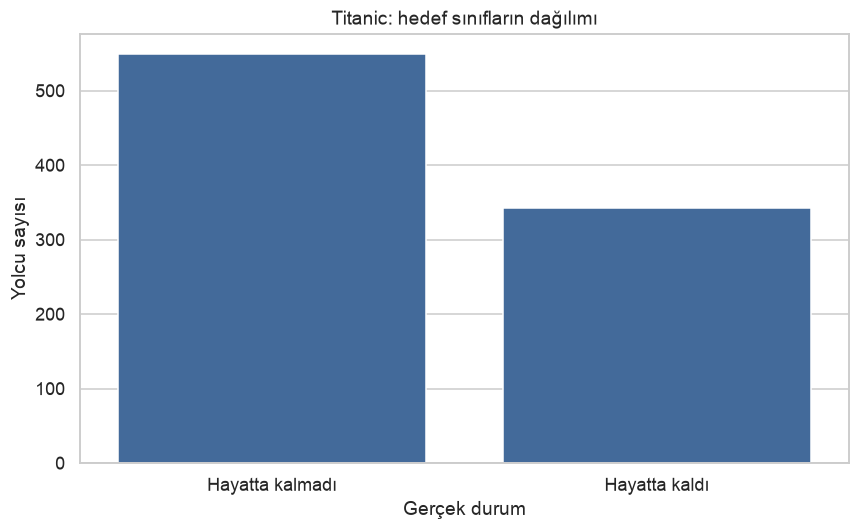

In [4]:
df.info()
display(df.isna().sum().rename("Eksik sayı").to_frame())
display(df["hayatta_kaldi"].value_counts().sort_index().rename("Yolcu sayısı"))
sns.countplot(data=df, x="hayatta_kaldi", color="#3569a8")
plt.xticks([0, 1], ["Hayatta kalmadı", "Hayatta kaldı"])
plt.xlabel("Gerçek durum"); plt.ylabel("Yolcu sayısı")
plt.title("Titanic: hedef sınıfların dağılımı"); plt.show()

**Çıktıyı nasıl okuyalım?**

Yaş gibi sütunlarda eksikler var. Her eksik satırı silmek veri kaybına yol açabilir. Sınıflar eşit değil; doğruluğu basit bir başlangıç modeliyle karşılaştıracağız.

## 5. Veriye grafikle bakmak

Yolcu sınıfıyla hayatta kalma arasındaki ilişkiyi inceliyoruz. Bu bir betimsel keşiftir; nedensellik kanıtı değildir.

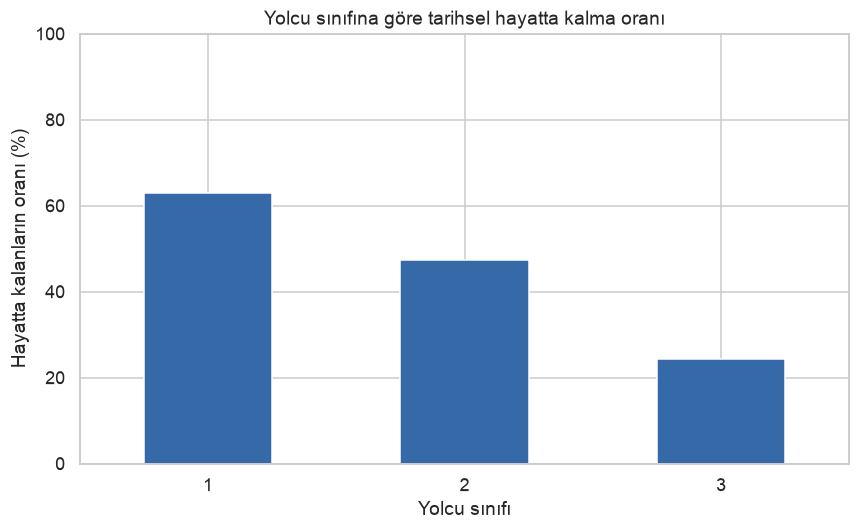

In [5]:
oranlar = df.groupby("yolcu_sinifi")["hayatta_kaldi"].mean().sort_index()
(oranlar * 100).plot.bar(color="#3569a8", rot=0)
plt.ylim(0, 100); plt.ylabel("Hayatta kalanların oranı (%)")
plt.xlabel("Yolcu sınıfı"); plt.title("Yolcu sınıfına göre tarihsel hayatta kalma oranı")
plt.show()

**Çıktıyı nasıl okuyalım?**

Çubukların yüksekliği her sınıftaki hayatta kalma oranıdır; yolcu sayısı değildir. Model bu tür ilişkilerden yararlanabilir. Verideki tarihsel eşitsizlikler modelin tahminlerine de yansır.

## 6. Eğitim ve test ayrımı

X girdiler, y doğru cevaptır. `%20` test en sona saklanır. `stratify`, sınıf oranını yaklaşık korur. `random_state=42` bölmeyi tekrarlanabilir kılar.

In [6]:
from sklearn.model_selection import train_test_split
X = df.drop(columns="hayatta_kaldi")
y = df["hayatta_kaldi"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Eğitim:", len(X_train), "| Test:", len(X_test))

Eğitim: 712 | Test: 179


**Çıktıyı nasıl okuyalım?**

Eksik doldurma ve ölçekleme bu ayrımdan sonra öğrenilecek. Tüm verinin medyanını kullanmak, testten eğitime bilgi taşır.

## 7. Veri hazırlama hattı

`SimpleImputer` eksikleri doldurur. `StandardScaler` sayıları ortak ölçeğe getirir. `OneHotEncoder` kategoriler için 0/1 sütunları üretir. `ColumnTransformer` iki sütun grubuna farklı işlem uygular. **Pipeline**, işlemleri modele bağlar; doğrulamada her katın hazırlığı kendi eğitim parçasından öğrenilir.

In [7]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
sayisal_hattı = Pipeline([
    ("eksik", SimpleImputer(strategy="median")),
    ("olcek", StandardScaler())])
kategorik_hattı = Pipeline([
    ("eksik", SimpleImputer(strategy="most_frequent")),
    ("kodla", OneHotEncoder(handle_unknown="ignore"))])
hazirlik = ColumnTransformer([
    ("sayisal", sayisal_hattı, sayisal),
    ("kategorik", kategorik_hattı, kategorik)])
lojistik = Pipeline([
    ("hazirlik", hazirlik),
    ("model", LogisticRegression(max_iter=1000))])
print(lojistik)

Pipeline(steps=[('hazirlik',
                 ColumnTransformer(transformers=[('sayisal',
                                                  Pipeline(steps=[('eksik',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('olcek',
                                                                   StandardScaler())]),
                                                  ['yas', 'kardes_es',
                                                   'ebeveyn_cocuk', 'ucret']),
                                                 ('kategorik',
                                                  Pipeline(steps=[('eksik',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('kodla',
                                                                   OneHotEncoder(handle_unknow

**Çıktıyı nasıl okuyalım?**

Lojistik regresyon, adında regresyon olsa da burada bir **sınıflandırma** algoritmasıdır. Öğrendiği skorları sınıf olasılığına dönüştürür; varsayılan eşikle 0/1 kararı verir.

## 8. Çapraz doğrulama ile model karşılaştırmak

Testi açmadan eğitim verisini 5 kata böleriz. Her turda dört kat eğitim, bir kat doğrulama olur. Aynı bölmelerde lojistik regresyon ve karar ağacını karşılaştırırız. `clone`, hazırlık hattının bağımsız bir kopyasını oluşturur.

In [8]:
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
agac = Pipeline([("hazirlik", clone(hazirlik)),
                 ("model", DecisionTreeClassifier(max_depth=4, random_state=42))])
modeller = {"Lojistik regresyon": lojistik, "Karar ağacı": agac}
kayitlar = []
for ad, aday in modeller.items():
    skorlar = cross_val_score(aday, X_train, y_train, cv=cv, scoring="accuracy")
    kayitlar.append({"Model": ad, "CV doğruluk": skorlar.mean(),
                     "Katlar arası std": skorlar.std()})
cv_tablosu = pd.DataFrame(kayitlar).sort_values("CV doğruluk", ascending=False)
display(cv_tablosu.round(3))

,Model,CV doğruluk,Katlar arası std
1,Karar ağacı,0.817,0.010
0,Lojistik regresyon,0.802,0.014


**Çıktıyı nasıl okuyalım?**

Ortalama doğruluk beş doğrulamanın özetidir. Standart sapma katlar arasındaki değişimi gösterir; güven aralığı değildir. Sonraki adımda burada öne çıkan modelin ayarını seçeceğiz.

## 9. Hiperparametre seçmek

Modelin veriden öğrendiği katsayılar **parametre**; bizim denediğimiz C veya ağaç derinliği **hiperparametre**dir. C küçüldükçe lojistik regresyonda düzenlileştirme güçlenir. `GridSearchCV`, ayarları yalnızca eğitim içindeki doğrulamayla karşılaştırır.

In [9]:
from sklearn.model_selection import GridSearchCV
secilen_ad = cv_tablosu.iloc[0]["Model"]
ayarlar = ({"model__C": [0.1, 1, 10]} if secilen_ad == "Lojistik regresyon"
           else {"model__max_depth": [2, 4, 6, 8]})
arama = GridSearchCV(modeller[secilen_ad], ayarlar, cv=cv, scoring="accuracy")
arama.fit(X_train, y_train)
son_model = arama.best_estimator_
print("Seçilen model:", secilen_ad)
print("En iyi ayar:", arama.best_params_)
print(f"En iyi doğrulama ortalaması: {arama.best_score_:.1%}")

Seçilen model: Karar ağacı
En iyi ayar: {'model__max_depth': 4}
En iyi doğrulama ortalaması: 81.7%


**Çıktıyı nasıl okuyalım?**

Bu skor ayar seçimi sırasında kullanıldığı için nihai bağımsız başarı değildir. Seçtiğimiz hattı test kümesinde bir kez değerlendireceğiz.

## 10. Son sınav: test verisi

`DummyClassifier`, her yolcuya eğitimdeki çoğunluk sınıfını söyler. Öğrenen modelin bunun üzerine ne kattığını ölçeriz. Matrisin satırları gerçek, sütunları tahmin edilen sınıftır.

Başlangıç doğruluğu: 61.5%
Model doğruluğu: 78.8%
                 precision    recall  f1-score   support

Hayatta kalmadı       0.77      0.94      0.84       110
  Hayatta kaldı       0.84      0.55      0.67        69

       accuracy                           0.79       179
      macro avg       0.81      0.74      0.76       179
   weighted avg       0.80      0.79      0.78       179



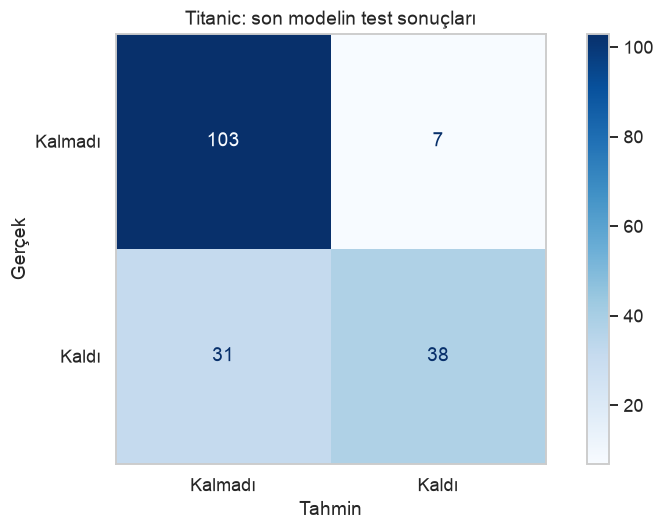

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
baslangic = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
tahmin = son_model.predict(X_test)
print(f"Başlangıç doğruluğu: {baslangic.score(X_test, y_test):.1%}")
print(f"Model doğruluğu: {accuracy_score(y_test, tahmin):.1%}")
print(classification_report(y_test, tahmin, target_names=["Hayatta kalmadı", "Hayatta kaldı"]))
ConfusionMatrixDisplay.from_predictions(y_test, tahmin, display_labels=["Kalmadı", "Kaldı"], cmap="Blues")
plt.grid(False); plt.xlabel("Tahmin"); plt.ylabel("Gerçek")
plt.title("Titanic: son modelin test sonuçları"); plt.show()

**Çıktıyı nasıl okuyalım?**

Köşegen doğru tahminleri gösterir. Precision, o sınıf diye tahmin edilenlerin ne kadarının doğru olduğunu; recall, gerçek sınıfın ne kadarının yakalandığını söyler. Tek bir bölmenin sonucu genel başarı garantisi değildir.

## 11. Yeni yolcular

Yeni tabloda aynı özellik adları bulunmalı. Eksik yaş varsa hattımız eğitim medyanıyla doldurur. Aşağıdaki kişiler ders için oluşturulmuş örnek profillerdir.

In [11]:
yeni_yolcular = pd.DataFrame({
    "yas": [25, np.nan], "kardes_es": [0, 1], "ebeveyn_cocuk": [0, 1],
    "ucret": [10.0, 60.0], "yolcu_sinifi": ["3", "1"],
    "cinsiyet": ["male", "female"], "binis_limani": ["S", "C"]})
# OpenML sürümünde sınıf kodları "1.0" biçimindeyse aynı gösterimi kullan.
if "1.0" in set(X_train["yolcu_sinifi"].dropna()):
    yeni_yolcular["yolcu_sinifi"] += ".0"
sonuc = yeni_yolcular.copy()
sonuc["tahmin"] = son_model.predict(yeni_yolcular)
pozitif_sutun = list(son_model.classes_).index(1)
sonuc["hayatta_kalma_olasiligi"] = son_model.predict_proba(yeni_yolcular)[:, pozitif_sutun]
display(sonuc.round(3))

,yas,kardes_es,ebeveyn_cocuk,ucret,yolcu_sinifi,cinsiyet,binis_limani,tahmin,hayatta_kalma_olasiligi
0,25.0,0,0,10.0,3,male,S,0,0.1
1,NaN,1,1,60.0,1,female,C,1,1.0


**Çıktıyı nasıl okuyalım?**

Bu değerler modelin tarihsel veri örüntülerinden ürettiği olasılık tahminleridir; kesinlik veya bireysel kader açıklaması değildir. Bu çalışma tarihsel bir öğretim örneğidir.

**Kontrol çalıştırmasından gözlem:** Son model testte %78,8 doğruluk verdi; çoğunluk başlangıcı %61,5 idi. Hayatta kalan 69 yolcunun 38’i yakalandı. Bu nedenle genel doğrulukla birlikte hayatta kalan sınıfın duyarlılığını da okumak gerekir.

Bu gözlem dosyadaki kayıtlı kontrol çıktısına aittir. Yeniden çalıştırmada yukarıdaki güncel çıktıları esas alın.

## Özet

| Kavram | Bu derste karşılığı |
|---|---|
| Eksik veri | Eğitim medyanı / en sık kategori |
| Kodlama | One-hot |
| Pipeline | Hazırlık ve modeli birlikte eğitmek |
| Doğrulama | 5 katlı model ve ayar seçimi |
| Test | Seçim bittikten sonra son değerlendirme |

### Tartışma soruları
1. Tüm verinin yaş medyanını kullanmak neden sakıncalı?
2. Lojistik regresyon neden sınıflandırma yapıyor?
3. Kurtarma botu sütunu başarıyı artırsa neden kullanmıyoruz?

### Öğrenci deneyleri
Önce sonucu tahmin edin, sonra kodu değiştirip çalıştırın. Ana deneyin sonuçlarıyla karışmaması için değiştirdiğiniz hücreden itibaren sırayla ilerleyin.
- Karar ağacı derinliğini 1 ve 10 yapın; eğitim içindeki CV skorlarını karşılaştırın.
- C listesini `[0.01, 0.1, 1, 10]` olarak değiştirin.
- Yaş sütununu özellik listesinden ve sayısal listeden çıkarıp eğitimdeki CV sonuçlarını karşılaştırın.

**Deney kaydı:** Değiştirdiğim ayar → beklediğim etki → gözlediğim sonuç → olası açıklama. Test kümesine tekrar tekrar bakarak en iyi ayarı seçmeyin; ayar seçimi eğitim içindeki doğrulamayla yapılır.